# Домашнее задание 1. Рекомендательные модели на Yambda-50M

Задача: для каждого пользователя построить top-10 новых треков (которые он ещё не слушал) на следующие две недели и сравнить пять моделей, реализованных с нуля.

| Модель | Файл |
|---|---|
| 1. Item-based kNN | `models/itemknn.py` |
| 2. iALS | `models/ials.py` |
| 3. EASE | `models/ease.py` |
| 4. Factorization Machine с метапризнаками | `models/fm.py` |
| 5. iALS с кастомным целевым сигналом | `models/ials_custom.py` |

Вспомогательный код: `models/base.py` (общий метод `recommend` и бейзлайн по популярности), `utils/data.py` (загрузка и подготовка данных), `utils/metrics.py` (метрики), `utils/experiment.py` (перебор по сетке).

## Запуск

```bash
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace experiments.ipynb
```

Данные (около 480 МБ) скачиваются с Hugging Face при первом запуске в папку `data/`. Вручную: файлы `flat/50m/multi_event.parquet`, `artist_item_mapping.parquet` и `album_item_mapping.parquet` из https://huggingface.co/datasets/yandex/yambda положить в `data/` с той же структурой.

Случайные зёрна зафиксированы (`SEED = 42`), параметры подвыборки и разбиения заданы в `SplitConfig`. Полный прогон занимает 30-60 минут на CPU.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import torch

from models import (EASE, CustomTargetALS, FactorizationMachine, ImplicitALS, ItemKNN,
                    PopularityRecommender, build_custom_target)
from utils.data import (DAY, GOOD_RATIO, Index, SplitConfig, aggregate_pairs, count_matrix,
                        download, item_fields, load_events, load_item_meta, make_subsample,
                        relevant_pairs, user_artist_bag)
from utils.experiment import grid, grid_search
from utils.metrics import evaluate, ground_truth_lists

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
K = 10
MAIN_METRIC = f"NDCG@{K}"

DATA_DIR = Path("data")
if not (DATA_DIR / "flat/50m/multi_event.parquet").exists():
    download(DATA_DIR)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
T0 = time.time()

## 1. Данные

**Yambda-50M** - открытый датасет Яндекс Музыки: [Hugging Face](https://huggingface.co/datasets/yandex/yambda), статья [arXiv:2505.22238](https://arxiv.org/abs/2505.22238). Это 10 000 пользователей из полной версии Yambda-5B. Используются файл `flat/50m/multi_event.parquet` со всеми событиями и таблицы соответствия трек - исполнитель и трек - альбом.

| Поле | Смысл |
|---|---|
| `uid` | идентификатор пользователя |
| `item_id` | идентификатор трека |
| `timestamp` | время события в секундах от начала лога (с шагом 5 с), около 300 дней |
| `is_organic` | 1 - пользователь выбрал трек сам, 0 - трек пришёл из рекомендаций |
| `event_type` | `listen`, `like`, `dislike`, `unlike`, `undislike` |
| `played_ratio_pct` | процент прослушанного трека (только для `listen`) |
| `track_length_seconds` | длина трека (только для `listen`) |
| `artist_id`, `album_id` | исполнитель и альбом трека |

Названий треков и исполнителей в датасете нет, только анонимные идентификаторы.

Что рекомендуется: треки, которые пользователь раньше не слушал. Повторные прослушивания составляют большую часть событий, но рекомендовать уже знакомые треки не имеет смысла.

Что считается релевантным: трек новый для пользователя, в окне оценки прослушан хотя бы раз на 50% и больше или лайкнут, и при этом нет дизлайка.

In [2]:
events = load_events(DATA_DIR)
meta = load_item_meta(DATA_DIR)
print(f"событий: {len(events):,}, пользователей: {events.uid.nunique():,}, треков: {events.item_id.nunique():,}")
print(f"период: {events.timestamp.max() / DAY:.1f} дней")
display(events.head())
display(events.event_type.value_counts().to_frame("events"))

событий: 47,790,449, пользователей: 10,000, треков: 934,057
период: 300.9 дней


,uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds,event_type
0,100,39420,8326270,0,100.0,170.0,listen
1,100,39420,1441281,0,100.0,105.0,listen
2,100,39625,286361,0,100.0,185.0,listen
3,100,40110,732449,0,100.0,240.0,listen
4,100,40360,3397170,0,46.0,130.0,listen


,events
event_type,
listen,46467212
like,881456
unlike,312972
dislike,107776
undislike,21033


## 2. EDA и подготовка данных

### 2.1 Пропуски и дубликаты

In [3]:
na = events.isna().groupby(events.event_type, observed=True).sum()
display(na)
dup_full = events.duplicated().sum()
dup_key = events.duplicated(["uid", "item_id", "timestamp", "event_type"]).sum()
print(f"полных дубликатов строк: {dup_full:,} ({dup_full / len(events):.3%})")
print(f"дубликатов по (uid, item_id, timestamp, event_type): {dup_key:,}")
print("треков без исполнителя:", events.item_id.drop_duplicates().isin(meta.dropna(subset=['artist_id']).item_id).eq(False).sum())
print("треков без альбома:", events.item_id.drop_duplicates().isin(meta.dropna(subset=['album_id']).item_id).eq(False).sum())

,uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds,event_type
event_type,,,,,,,
dislike,0,0,0,0,107776,107776,0
like,0,0,0,0,881456,881456,0
listen,0,0,0,0,0,0,0
undislike,0,0,0,0,21033,21033,0
unlike,0,0,0,0,312972,312972,0


полных дубликатов строк: 236,230 (0.494%)
дубликатов по (uid, item_id, timestamp, event_type): 598,641


треков без исполнителя: 5607


треков без альбома: 32250


Пропуски в `played_ratio_pct` и `track_length_seconds` есть только у событий `like / dislike / unlike / undislike`, у которых нет прослушивания. Дубликаты строк - это одинаковые события внутри одного 5-секундного интервала. Дальше события агрегируются в пары (пользователь, трек), поэтому дубликаты лишь немного увеличивают число прослушиваний и отдельно не удаляются.

### 2.2 Активность пользователей, популярность треков, прослушивания

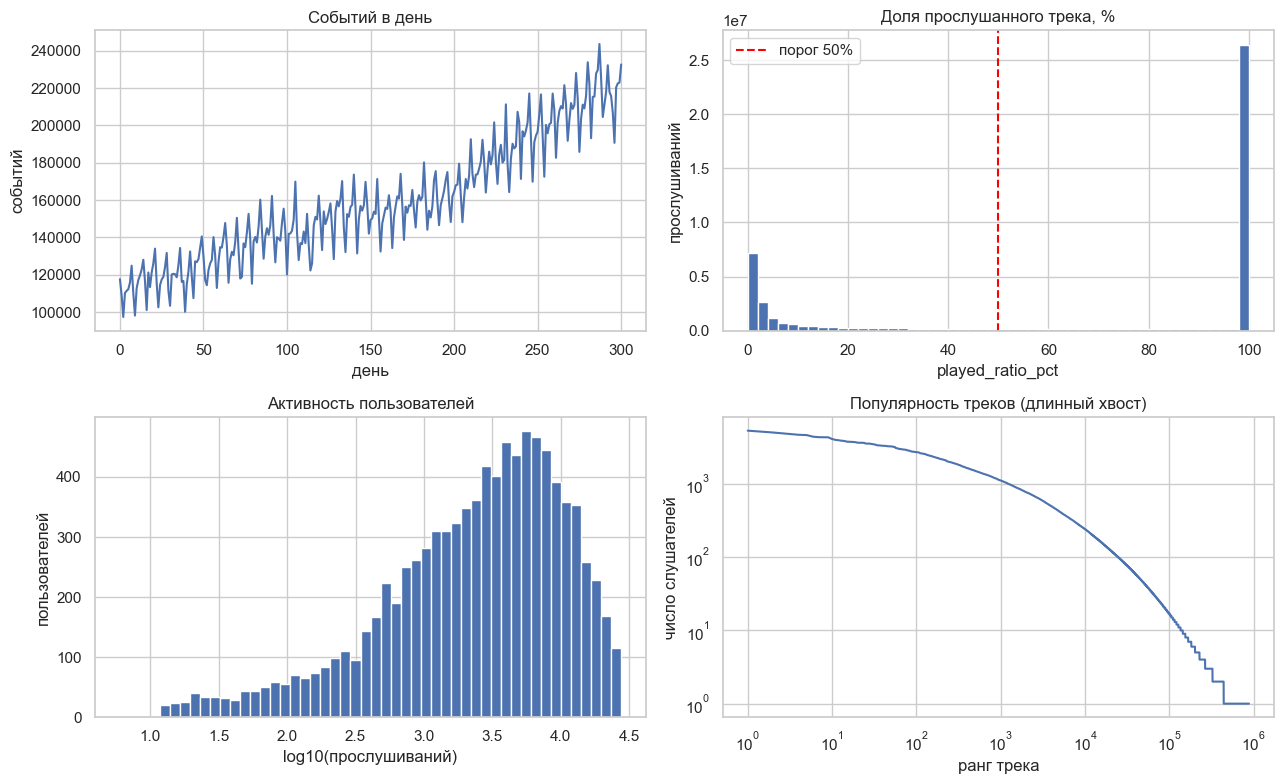

прослушиваний на пользователя: медиана 3024, среднее 5030, max 27,617
треков со 1 слушателем: 49.9%; с ≥100 слушателями: 24,774
уникальных пар (user, track): 13,268,889 -> 71.4% прослушиваний - повторы
прослушиваний ≥50%: 63.4%; органических событий: 52.1%


разреженность полной матрицы: 99.85794%


In [4]:
listens = events[events.event_type == "listen"]
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

per_day = (events.timestamp // DAY).value_counts().sort_index()
ax[0, 0].plot(per_day.index, per_day.values)
ax[0, 0].set(title="Событий в день", xlabel="день", ylabel="событий")

ax[0, 1].hist(listens.played_ratio_pct.clip(upper=100), bins=50)
ax[0, 1].axvline(GOOD_RATIO, color="red", ls="--", label=f"порог {GOOD_RATIO}%")
ax[0, 1].set(title="Доля прослушанного трека, %", xlabel="played_ratio_pct", ylabel="прослушиваний")
ax[0, 1].legend()

user_act = listens.groupby("uid").size()
ax[1, 0].hist(np.log10(user_act), bins=50)
ax[1, 0].set(title="Активность пользователей", xlabel="log10(прослушиваний)", ylabel="пользователей")

item_pop = listens.groupby("item_id").uid.nunique().sort_values(ascending=False).to_numpy()
ax[1, 1].loglog(np.arange(1, len(item_pop) + 1), item_pop)
ax[1, 1].set(title="Популярность треков (длинный хвост)", xlabel="ранг трека", ylabel="число слушателей")
plt.tight_layout()
plt.show()

n_pairs = listens[["uid", "item_id"]].drop_duplicates().shape[0]
print(f"прослушиваний на пользователя: медиана {user_act.median():.0f}, среднее {user_act.mean():.0f}, max {user_act.max():,}")
print(f"треков со 1 слушателем: {(item_pop == 1).mean():.1%}; с ≥100 слушателями: {(item_pop >= 100).sum():,}")
print(f"уникальных пар (user, track): {n_pairs:,} -> {1 - n_pairs / len(listens):.1%} прослушиваний - повторы")
print(f"прослушиваний ≥{GOOD_RATIO}%: {(listens.played_ratio_pct >= GOOD_RATIO).mean():.1%}; органических событий: {events.is_organic.mean():.1%}")
print(f"разреженность полной матрицы: {1 - n_pairs / (events.uid.nunique() * events.item_id.nunique()):.5%}")

По графикам:
* популярность треков имеет длинный хвост: у половины треков один слушатель, матрица очень разреженная;
* 71% прослушиваний - повторы знакомых треков, поэтому в задаче рекомендуются только новые треки;
* распределение `played_ratio_pct` бимодальное: трек либо пропускают в первые секунды, либо дослушивают. Порог 50% разделяет эти два случая. Сам факт прослушивания оказывается шумным сигналом;
* около половины событий органические, остальные пришли из рекомендаций.

### 2.3 Метаданные треков

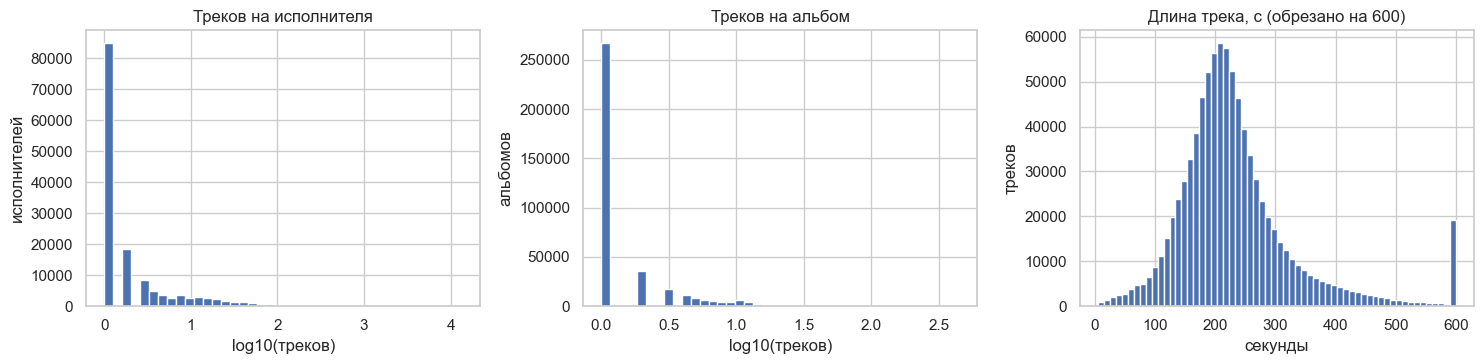

исполнителей: 144,485, альбомов: 375,234
треков на исполнителя: медиана 1, среднее 6.0
длина трека: медиана 215 c


In [5]:
item_meta = meta[meta.item_id.isin(listens.item_id.unique())]
tracks_per_artist = item_meta.groupby("artist_id").size()
tracks_per_album = item_meta.groupby("album_id").size()
length = listens.groupby("item_id").track_length_seconds.median()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(np.log10(tracks_per_artist), bins=40)
ax[0].set(title="Треков на исполнителя", xlabel="log10(треков)", ylabel="исполнителей")
ax[1].hist(np.log10(tracks_per_album), bins=40)
ax[1].set(title="Треков на альбом", xlabel="log10(треков)", ylabel="альбомов")
ax[2].hist(length.clip(upper=600), bins=60)
ax[2].set(title="Длина трека, с (обрезано на 600)", xlabel="секунды", ylabel="треков")
plt.tight_layout()
plt.show()
print(f"исполнителей: {item_meta.artist_id.nunique():,}, альбомов: {item_meta.album_id.nunique():,}")
print(f"треков на исполнителя: медиана {tracks_per_artist.median():.0f}, среднее {tracks_per_artist.mean():.1f}")
print(f"длина трека: медиана {length.median():.0f} c")

У трека есть исполнитель и альбом, на одного исполнителя приходится в среднем 6 треков. Длина трека отделяет нетипичный контент (подкасты, длинные композиции). Эти признаки не меняются со временем и известны в момент рекомендации, поэтому их можно использовать в FM.

### 2.4 Подвыборка

Полные данные (47.8 млн событий, 13.3 млн пар) превышают ограничение в 2 млн взаимодействий, а матрица item × item для EASE была бы слишком большой. Подвыборка строится функцией `utils.data.make_subsample`, причём каталог и пользователи выбираются только по данным до начала валидации:

1. Каталог: 10 000 треков с наибольшим числом уникальных слушателей.
2. Пользователи: среди пользователей, у которых не меньше 20 разных треков из каталога, случайно (`seed=42`) выбираются 2 500.
3. Остаются все события этих пользователей с треками из каталога.

Взаимодействие - пара (пользователь, трек) с агрегированными событиями: число прослушиваний, число прослушиваний на 50% и больше, наличие лайка и дизлайка (с учётом их отмены), время первого и последнего события.

In [6]:
cfg = SplitConfig()
sub, info = make_subsample(events, cfg)
pairs_all = aggregate_pairs(sub)
print(cfg)
print(f"минимум слушателей у трека каталога: {info['min_listeners']}, подходящих пользователей: {info['n_eligible_users']:,}")

summary = pd.DataFrame({
    "исходные данные": [len(events), events.uid.nunique(), events.item_id.nunique(), n_pairs],
    "подвыборка": [len(sub), sub.uid.nunique(), sub.item_id.nunique(), len(pairs_all)],
}, index=["событий", "пользователей", "треков", "взаимодействий (пар user-track)"])
display(summary.style.format("{:,}"))
density = len(pairs_all) / (sub.uid.nunique() * sub.item_id.nunique())
print(f"плотность матрицы подвыборки: {density:.2%} (разреженность {1 - density:.2%})")
assert 100_000 <= len(pairs_all) <= 2_000_000 and sub.uid.nunique() >= 1000 and sub.item_id.nunique() >= 1000
del listens

SplitConfig(n_items=10000, n_users=2500, min_user_pairs=20, val_days=14, test_days=14, seed=42)
минимум слушателей у трека каталога: 211, подходящих пользователей: 8,435


,исходные данные,подвыборка
событий,"47,790,449","6,889,461"
пользователей,"10,000","2,500"
треков,"934,057","10,000"
взаимодействий (пар user-track),"13,268,889","1,707,910"


плотность матрицы подвыборки: 6.83% (разреженность 93.17%)


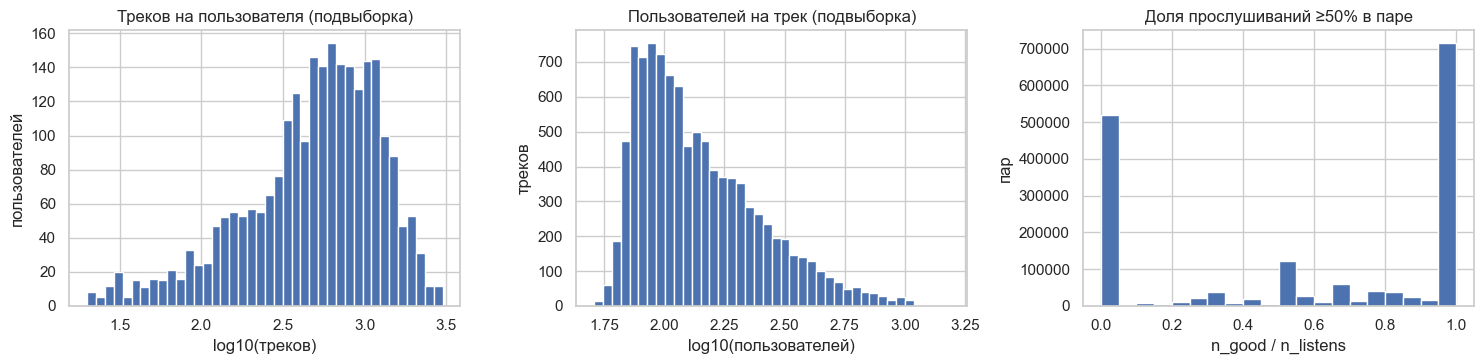

пар только с пропусками (нет ни одного прослушивания ≥50%): 30.6%
пар с лайком: 5.22%, с дизлайком: 0.73%


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(np.log10(pairs_all.groupby("uid").size()), bins=40)
ax[0].set(title="Треков на пользователя (подвыборка)", xlabel="log10(треков)", ylabel="пользователей")
ax[1].hist(np.log10(pairs_all.groupby("item_id").size()), bins=40)
ax[1].set(title="Пользователей на трек (подвыборка)", xlabel="log10(пользователей)", ylabel="треков")
good_share = pairs_all.n_good / pairs_all.n_listens.clip(lower=1)
ax[2].hist(good_share[pairs_all.n_listens > 0], bins=20)
ax[2].set(title="Доля прослушиваний ≥50% в паре", xlabel="n_good / n_listens", ylabel="пар")
plt.tight_layout()
plt.show()
print(f"пар только с пропусками (нет ни одного прослушивания ≥50%): {(pairs_all.n_good == 0).mean():.1%}")
print(f"пар с лайком: {pairs_all.liked.mean():.2%}, с дизлайком: {pairs_all.disliked.mean():.2%}")

Почти треть пар состоит только из пропусков: трек включали, но ни разу не дослушали до половины. В обычном iALS такая пара считается таким же позитивом, как любимый трек.

## 3. Протокол оценки

* Разбиение по времени, общее для всех пользователей: последние 14 дней - test, предыдущие 14 дней - validation, остальное - train.
* Подбор гиперпараметров: обучение на train, история пользователя - train, оценка на validation.
* Финальное сравнение: модели с выбранными параметрами обучаются на train + validation и оцениваются на test. Для выбора параметров test не используется.
* Кандидаты: все 10 000 треков каталога, кроме тех, с которыми у пользователя уже были события. Для всех моделей одинаково.
* Релевантность одна для всех моделей и не зависит от обучающего таргета: новый трек, прослушанный в окне на 50% и больше или лайкнутый, без дизлайка.
* В оценке участвуют пользователи хотя бы с одним релевантным треком в окне.
* Холодных пользователей нет: у всех выбранных пользователей есть история до валидации. Треков вне каталога тоже нет, так как каталог фиксируется заранее.

In [8]:
t_val, t_test = info["t_val"], info["t_test"]
ev_train = sub[sub.timestamp < t_val]
ev_val = sub[(sub.timestamp >= t_val) & (sub.timestamp < t_test)]
ev_test = sub[sub.timestamp >= t_test]
ev_trval = sub[sub.timestamp < t_test]

pairs_train, pairs_val_win, pairs_test_win, pairs_trval = map(aggregate_pairs, [ev_train, ev_val, ev_test, ev_trval])
idx = Index(info["users"], info["catalogue"])

rel_val = idx.add(relevant_pairs(pairs_val_win, pairs_train))
rel_test = idx.add(relevant_pairs(pairs_test_win, pairs_trval))
gt_val, gt_test = ground_truth_lists(rel_val, len(idx.users)), ground_truth_lists(rel_test, len(idx.users))
users_val, users_test = np.sort(rel_val.uidx.unique()), np.sort(rel_test.uidx.unique())

split_stats = pd.DataFrame({
    "событий": [len(ev_train), len(ev_val), len(ev_test)],
    "пар user-track": [len(pairs_train), len(pairs_val_win), len(pairs_test_win)],
    "пользователей в оценке": [np.nan, len(users_val), len(users_test)],
    "релевантных пар": [np.nan, len(rel_val), len(rel_test)],
    "релевантных на пользователя (медиана)": [np.nan, rel_val.groupby("uidx").size().median(), rel_test.groupby("uidx").size().median()],
}, index=["train", "validation", "test"])
display(split_stats)
new_share_val = 1 - len(pairs_val_win.merge(pairs_train[["uid", "item_id"]])) / len(pairs_val_win)
print(f"доля пар окна validation, новых для пользователя: {new_share_val:.1%}")

,событий,пар user-track,пользователей в оценке,релевантных пар,релевантных на пользователя (медиана)
train,6127032,1560980,NaN,NaN,NaN
validation,390273,234076,1958.0,46475.0,13.0
test,372156,235027,2072.0,47147.0,12.0


доля пар окна validation, новых для пользователя: 31.4%


Метрики при K = 10, основная метрика выбрана до подбора параметров - NDCG@10.

* NDCG@10 учитывает позиции попаданий в списке, а пользователь в первую очередь видит верх списка.
  $\mathrm{DCG@10}=\sum_{r=1}^{10}\frac{\mathrm{rel}_r}{\log_2(r+1)}$, $\mathrm{NDCG@10}=\mathrm{DCG@10}/\mathrm{IDCG@10}$, среднее по пользователям.
* Recall@10 $=\frac{|\text{top-10}\cap\text{Rel}_u|}{\min(|\text{Rel}_u|,10)}$ - доля найденных релевантных треков (нормировка на минимум, чтобы максимум был равен 1).
* Дополнительно: HitRate@10 (доля пользователей хотя бы с одним попаданием), MRR@10 и Coverage@10 (доля каталога, попавшая хотя бы в один top-10).

In [9]:
def build_inputs(pairs):
    X = count_matrix(pairs, idx)
    fields, artist = item_fields(sub, meta, idx, X)
    bag = user_artist_bag(X, artist)
    return dict(X=X, pairs=idx.add(pairs), fields=fields, bag=bag)

STAGES = {
    "val": dict(**build_inputs(pairs_train), users=users_val, gt=gt_val),
    "test": dict(**build_inputs(pairs_trval), users=users_test, gt=gt_test),
}
N_ITEMS = len(idx.items)

def evaluate_model(model, stage="val"):
    s = STAGES[stage]
    recs = model.recommend(s["users"], s["X"], k=K)
    return evaluate(recs, s["users"], s["gt"], N_ITEMS, k=K)

print({k: v.max() + 1 for k, v in STAGES["val"]["fields"].items()}, "| user-artist bag nnz:", STAGES["val"]["bag"].nnz)

{'artist': np.int64(3810), 'album': np.int64(7869), 'length_bucket': np.int64(8), 'pop_bucket': np.int64(10)} | user-artist bag nnz: 120788


## 4. Модели и подбор гиперпараметров

Все модели наследуют `BaseRecommender`: модель возвращает матрицу скоров, а общий метод `recommend` ставит $-\infty$ уже известным трекам и берёт top-10. Для каждой модели перебирается сетка параметров, лучшая конфигурация выбирается по NDCG@10 на validation.

### 4.0 Бейзлайн: популярность
Скор трека - число уникальных слушателей в train.

In [10]:
results_val = {}
pop = PopularityRecommender().fit(STAGES["val"]["X"])
results_val["Popularity"] = evaluate_model(pop)
results_val["Popularity"]

{'NDCG@10': 0.0260870251836411,
 'Recall@10': 0.025718055352886814,
 'HitRate@10': 0.14147088866189989,
 'MRR@10': 0.059861252979230506,
 'Coverage@10': 0.0161}

### 4.1 Item-based kNN

$x_i$ - столбец трека $i$ в матрице пользователь × трек с весами $r_{ui}\in\{1,\ \log(1+\#\text{прослушиваний})\}$. Сходство - косинус со сжатием $h$, которое уменьшает сходство треков с малым числом общих слушателей:
$$s_{ij}=\frac{x_i^\top x_j}{\|x_i\|\,\|x_j\|+h}.$$
Для каждого трека хранятся $k$ ближайших соседей. Скор: $\hat y_{uj}=\sum_{i\in I(u)} r_{ui}\,s_{ij}$. Сетка: $k\in\{50,200,1000,3000\}$, $h\in\{0,20,100\}$, веса ∈ {binary, log}.

In [11]:
X_val = STAGES["val"]["X"]
knn_grid = grid_search("ItemKNN", grid(n_neighbors=[50, 200, 1000, 3000], shrink=[0, 20, 100], weighting=["binary", "log"]),
                       lambda c: ItemKNN(**c).fit(X_val), evaluate_model, verbose=False)
display(knn_grid.head(8))

,n_neighbors,shrink,weighting,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,time_s
0,1000,0,log,0.047138,0.046285,0.239019,0.106678,0.1085,5.3
1,3000,0,log,0.046868,0.045505,0.238509,0.107068,0.1127,11.1
2,3000,20,log,0.046156,0.045543,0.236466,0.104168,0.0979,9.6
3,200,0,log,0.045928,0.045505,0.233912,0.101834,0.1421,3.3
4,1000,20,log,0.045899,0.045399,0.232891,0.103449,0.0940,5.3
5,200,20,log,0.045735,0.045592,0.233912,0.101568,0.1256,3.6
6,50,20,log,0.045051,0.045641,0.240552,0.099016,0.1420,2.9
7,50,0,log,0.044756,0.045963,0.246170,0.098165,0.1608,2.8


### 4.2 iALS

Для всех пар $(u,i)$: предпочтение $p_{ui}=\mathbb 1[r_{ui}>0]$, уверенность $c_{ui}=1+\alpha\log(1+r_{ui})$, где $r_{ui}$ - число прослушиваний. Для ненаблюдаемых пар $p=0$, $c=1$.
$$\min_{X,Y}\sum_{u,i}c_{ui}\,(p_{ui}-x_u^\top y_i)^2+\lambda\Big(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\Big).$$
При фиксированном $Y$ для каждого пользователя получается взвешенная гребневая регрессия:
$$x_u=\big(Y^\top Y+Y^\top(C_u-I)Y+\lambda I\big)^{-1}Y^\top C_u\,p_u,$$
где $Y^\top Y$ считается один раз на шаг, а поправка зависит только от треков пользователя. Шаг для треков симметричен, всего 10 итераций. Сетка: $d\in\{64,128\}$, $\lambda\in\{1,10,30\}$, $\alpha\in\{0.5,2,10\}$.

In [12]:
ials_grid = grid_search("iALS", grid(factors=[64, 128], reg=[1.0, 10.0, 30.0], alpha=[0.5, 2.0, 10.0]),
                        lambda c: ImplicitALS(iterations=10, seed=SEED, **c).fit(X_val), evaluate_model, verbose=False)
display(ials_grid.head(8))

,factors,reg,alpha,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,time_s
0,128,1.0,0.5,0.057500,0.058913,0.300817,0.124686,0.4311,88.8
1,128,10.0,0.5,0.057311,0.058246,0.300817,0.125428,0.4052,84.1
2,128,30.0,0.5,0.057009,0.058388,0.294178,0.122615,0.3262,86.6
3,64,10.0,2.0,0.056611,0.057908,0.291113,0.120986,0.4195,20.9
4,128,10.0,2.0,0.056076,0.058399,0.296221,0.121121,0.4632,85.2
5,64,10.0,0.5,0.055908,0.057804,0.296221,0.119799,0.3471,20.7
6,64,1.0,0.5,0.055843,0.057577,0.298264,0.120418,0.3648,36.0
7,128,1.0,2.0,0.055790,0.058605,0.295710,0.120303,0.4891,85.7


### 4.3 EASE

Линейная модель трек - трек с нулевой диагональю:
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2\quad\text{s.t.}\ \operatorname{diag}(B)=0.$$
Решение в замкнутой форме: $G=X^\top X+\lambda I$, $P=G^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$, $B_{jj}=0$. Матрица $G$ симметричная и положительно определённая, поэтому обращается через разложение Холецкого. Скор: $\hat y_u=x_u^\top B$. Сетка: $\lambda\in\{50,200,500,1000,2000,5000\}$, веса ∈ {binary, log}.

,reg,weighting,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,time_s
0,1000.0,log,0.060935,0.062354,0.307967,0.131442,0.3784,19.2
1,500.0,log,0.060739,0.062923,0.317671,0.130419,0.4096,19.0
2,2000.0,log,0.060131,0.061364,0.303371,0.130860,0.3353,19.0
3,200.0,log,0.058435,0.060963,0.314607,0.127528,0.4320,19.8
4,500.0,binary,0.058200,0.059150,0.305924,0.128077,0.3659,20.4
5,200.0,binary,0.057564,0.059047,0.306946,0.127045,0.4034,21.5
6,1000.0,binary,0.057496,0.058200,0.297242,0.125350,0.3254,19.2
7,5000.0,log,0.056893,0.056650,0.287028,0.126563,0.2643,19.3


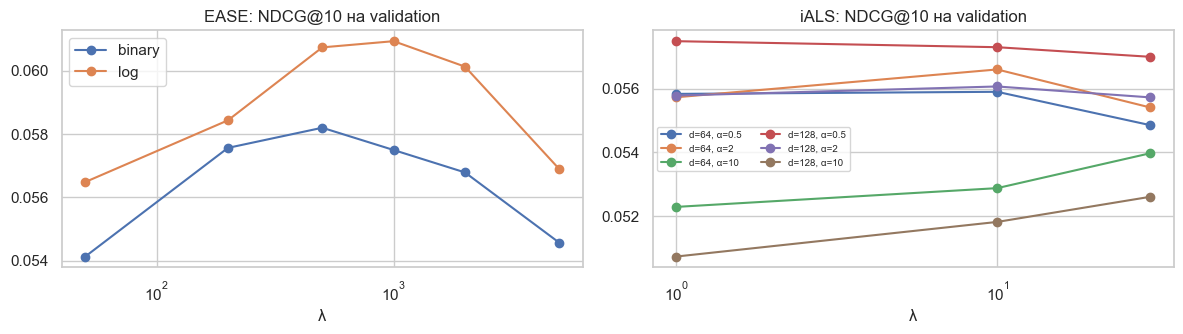

In [13]:
ease_grid = grid_search("EASE", grid(reg=[50.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0], weighting=["binary", "log"]),
                        lambda c: EASE(**c).fit(X_val), evaluate_model, verbose=False)
display(ease_grid.head(8))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for w, g in ease_grid.groupby("weighting"):
    g = g.sort_values("reg"); ax[0].semilogx(g.reg, g[MAIN_METRIC], "o-", label=w)
ax[0].set(title="EASE: NDCG@10 на validation", xlabel="λ"); ax[0].legend()
for (d, a), g in ials_grid.groupby(["factors", "alpha"]):
    g = g.sort_values("reg"); ax[1].semilogx(g.reg, g[MAIN_METRIC], "o-", label=f"d={d}, α={a:g}")
ax[1].set(title="iALS: NDCG@10 на validation", xlabel="λ"); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

### 4.4 Factorization Machine с метапризнаками

Пара (пользователь, трек) описывается разреженным вектором признаков $x$:
* пользователь: one-hot ID и 50 самых прослушиваемых в train исполнителей пользователя (веса $\log(1+\#\text{прослушиваний})$, сумма весов равна 1);
* трек: one-hot ID, исполнитель, альбом, группа по длине (8 квантилей), группа по популярности в train (10 групп в лог-шкале).

Признаки известны в момент рекомендации: метаданные статичны, профиль исполнителей и популярность считаются только по обучающему периоду. Исполнитель и альбом связывают треки одного исполнителя, профиль исполнителей описывает вкус пользователя, длина отделяет нетипичный контент, популярность позволяет учесть отношение пользователя к хитам.

Модель:
$$\hat y(x)=w_0+\sum_f w_f x_f+\sum_{f<g}\langle v_f,v_g\rangle x_f x_g=w_0+\sum_f w_fx_f+\tfrac12\Big(\big\|\textstyle\sum_f v_fx_f\big\|^2-\sum_f\|v_f\|^2x_f^2\Big).$$
Если разделить признаки на пользовательские $U$ и трековые $I$, то $\hat y(u,i)=\text{const}(u)+\langle V_U(u),V_I(i)\rangle+b(i)$, где $b(i)=\sum_{f\in I}w_f+\tfrac12(\|V_I(i)\|^2-\sum_{f\in I}\|v_f\|^2)$. Слагаемое $\text{const}(u)$ не влияет на порядок треков, поэтому скоры для всего каталога считаются одним матричным умножением.

Обучение - BPR-лосс: для позитива $i$ из train и случайного негатива $j$
$$L=-\log\sigma(\hat y(u,i)-\hat y(u,j))+\lambda\big(\|V_U(u)\|^2+\textstyle\sum_{f\in I(i)}\|v_f\|^2+\sum_{f\in I(j)}\|v_f\|^2\big),$$
оптимизатор Adam. Подбираются набор признаков, $\lambda$ и число эпох. Для оценки влияния метаданных та же модель обучается только на ID (FM без метаданных).

In [14]:
def fm_inputs(stage, feature_set):
    s = STAGES[stage]
    fields = {k: s["fields"][k] for k in feature_set if k in s["fields"]}
    bag = s["bag"] if "user_artists" in feature_set else None
    return s["X"], fields, bag

FEATURE_SETS = {
    "all": ("artist", "album", "length_bucket", "pop_bucket", "user_artists"),
    "artist+user_artists": ("artist", "user_artists"),
    "artist+album+length": ("artist", "album", "length_bucket"),
    "user_artists": ("user_artists",),
}
FM_EPOCHS = 15

def fm_search(feature_sets, regs, stage="val"):
    rows = []
    for fs in feature_sets:
        for reg in regs:
            t, curve = time.time(), []
            def cb(m, epoch):
                curve.append({"features": fs, "reg": reg, "epoch": epoch, **evaluate_model(m, stage)})
            FactorizationMachine(factors=64, lr=0.005, reg=reg, epochs=FM_EPOCHS, seed=SEED).fit(
                *fm_inputs(stage, FEATURE_SETS.get(fs, ())), callback=cb)
            best = max(curve, key=lambda r: r[MAIN_METRIC])
            print(f"[FM] {fs:22s} reg={reg:g}: best epoch {best['epoch']}, {MAIN_METRIC}={best[MAIN_METRIC]:.4f} ({time.time() - t:.0f}s)", flush=True)
            rows += curve
    return pd.DataFrame(rows)

fm_curves = fm_search(list(FEATURE_SETS), [1e-4, 1e-3])
fm_id_curves = fm_search(["id_only"], [1e-4, 1e-3])
fm_grid = fm_curves.sort_values(MAIN_METRIC, ascending=False).reset_index(drop=True)
display(fm_grid.head(8))

[FM] all                    reg=0.0001: best epoch 11, NDCG@10=0.0494 (140s)


[FM] all                    reg=0.001: best epoch 11, NDCG@10=0.0505 (137s)


[FM] artist+user_artists    reg=0.0001: best epoch 14, NDCG@10=0.0544 (76s)


[FM] artist+user_artists    reg=0.001: best epoch 14, NDCG@10=0.0549 (81s)


[FM] artist+album+length    reg=0.0001: best epoch 11, NDCG@10=0.0489 (87s)


...

[FM] user_artists           reg=0.0001: best epoch 11, NDCG@10=0.0570 (61s)


[FM] user_artists           reg=0.001: best epoch 14, NDCG@10=0.0570 (58s)


[FM] id_only                reg=0.0001: best epoch 11, NDCG@10=0.0580 (39s)


[FM] id_only                reg=0.001: best epoch 11, NDCG@10=0.0579 (35s)


,features,reg,epoch,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10
0,user_artists,0.0010,14,0.056998,0.059079,0.296731,0.120622,0.5884
1,user_artists,0.0001,11,0.056963,0.058374,0.297242,0.125119,0.5574
2,user_artists,0.0010,11,0.056607,0.057673,0.289581,0.124562,0.5354
3,user_artists,0.0010,15,0.055832,0.058592,0.299285,0.119054,0.5953
4,user_artists,0.0010,13,0.055260,0.055530,0.283453,0.116682,0.5696
5,artist+user_artists,0.0010,14,0.054942,0.054461,0.278856,0.121464,0.4770
6,user_artists,0.0001,14,0.054854,0.057179,0.292646,0.116111,0.6143
7,artist+user_artists,0.0010,11,0.054762,0.055600,0.283453,0.119876,0.4466


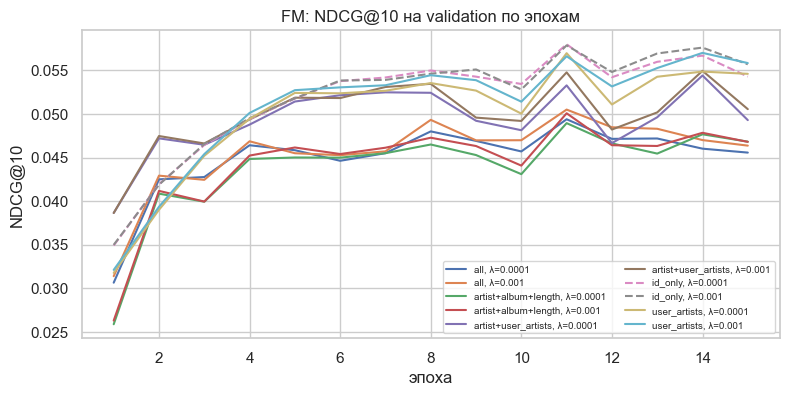

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
for (fs, reg), g in pd.concat([fm_curves, fm_id_curves]).groupby(["features", "reg"]):
    ax.plot(g.epoch, g[MAIN_METRIC], "--" if fs == "id_only" else "-", label=f"{fs}, λ={reg:g}")
ax.set(title="FM: NDCG@10 на validation по эпохам", xlabel="эпоха", ylabel="NDCG@10")
ax.legend(fontsize=7, ncol=2)
plt.show()

### 4.5 iALS с кастомным целевым сигналом

В iALS $p_{ui}=1$ для любого прослушанного трека, хотя около трети пар состоит только из пропусков. Лайки и дизлайки при этом не используются.

Пусть $n_{ui}$ - число прослушиваний, $g_{ui}$ - число прослушиваний на 50% и больше. Сглаженная доля хороших прослушиваний:
$$q_{ui}=\frac{g_{ui}+\kappa\mu}{n_{ui}+\kappa},$$
где $\mu$ - доля хороших прослушиваний по всему train, $\kappa$ - сила сглаживания: при одном прослушивании оценка близка к $\mu$, при многих пропусках стремится к 0, при многих полных прослушиваниях - к 1. Целевой сигнал:
$$p_{ui}=\begin{cases}1,&\text{есть лайк}\\0,&\text{есть дизлайк}\\q_{ui}^{\gamma},&\text{иначе.}\end{cases}$$
При $\gamma>1$ сигнал строже, при $\gamma<1$ мягче. Пропущенные треки получают $p\approx0$ при уверенности $c_{ui}>1$, то есть становятся негативами сильнее, чем ненаблюдаемые пары.

Уверенность $c_{ui}=1+\alpha\log(1+n_{ui})$ такая же, как в базовом iALS, параметры $d,\lambda,\alpha$ и число итераций взяты у лучшего iALS. Меняется только целевое значение $p_{ui}\in[0,1]$, формула обновления остаётся прежней. Критерий релевантности на test не меняется. Подбираются только параметры таргета: $\kappa\in\{0.1,0.5,2\}$, $\gamma\in\{0.5,1,2\}$.

лучший iALS: {'factors': 128, 'reg': 1.0, 'alpha': 0.5} | μ = 0.636


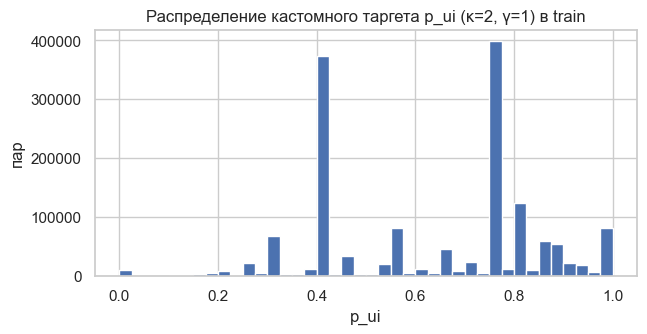

пар с p < 0.5: 36.1% - в бейзлайне все они имели p = 1


,kappa,gamma,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,time_s
0,0.5,1.0,0.064259,0.065722,0.331461,0.137480,0.4337,79.0
1,2.0,1.0,0.064079,0.066460,0.327886,0.136821,0.4363,86.7
2,0.5,2.0,0.063518,0.064650,0.317671,0.135495,0.4199,89.3
3,0.1,1.0,0.063455,0.064811,0.318693,0.135100,0.4290,85.6
4,0.1,2.0,0.063376,0.064639,0.318693,0.134082,0.4122,86.5
5,2.0,2.0,0.063101,0.063957,0.327375,0.136282,0.4199,86.6
6,0.1,0.5,0.063073,0.065406,0.321757,0.133144,0.4390,89.1
7,0.5,0.5,0.062565,0.064051,0.324311,0.133595,0.4415,89.0
8,2.0,0.5,0.061201,0.063153,0.321757,0.131816,0.4425,87.1


In [16]:
ials_best = ials_grid.iloc[0][["factors", "reg", "alpha"]].to_dict()
ials_best["factors"] = int(ials_best["factors"])
MU = float((pairs_train.n_good.sum()) / pairs_train.n_listens.clip(lower=1).sum())
print("лучший iALS:", ials_best, f"| μ = {MU:.3f}")

pv = STAGES["val"]["pairs"]
_, P_ex = build_custom_target(pv, idx.shape, kappa=2.0, mu=MU, gamma=1.0)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(P_ex.data, bins=40)
ax.set(title="Распределение кастомного таргета p_ui (κ=2, γ=1) в train", xlabel="p_ui", ylabel="пар")
plt.show()
print(f"пар с p < 0.5: {(P_ex.data < 0.5).mean():.1%} - в бейзлайне все они имели p = 1")

custom_grid = grid_search("iALS-custom", grid(kappa=[0.1, 0.5, 2.0], gamma=[0.5, 1.0, 2.0]),
                          lambda c: CustomTargetALS(mu=MU, iterations=10, seed=SEED, **ials_best, **c).fit_pairs(pv, idx.shape),
                          evaluate_model, verbose=False)
display(custom_grid)

### 4.6 Итоги подбора на validation

In [17]:
best = {
    "ItemKNN": knn_grid.iloc[0], "iALS": ials_grid.iloc[0], "EASE": ease_grid.iloc[0],
    "FM (метаданные)": fm_grid.iloc[0], "iALS + кастомный таргет": custom_grid.iloc[0],
}
fm_id_best = fm_id_curves.sort_values(MAIN_METRIC, ascending=False).iloc[0]
metric_cols = [f"{m}@{K}" for m in ["NDCG", "Recall", "HitRate", "MRR", "Coverage"]]
params = {
    "ItemKNN": ["n_neighbors", "shrink", "weighting"], "iALS": ["factors", "reg", "alpha"],
    "EASE": ["reg", "weighting"], "FM (метаданные)": ["features", "reg", "epoch"],
    "iALS + кастомный таргет": ["kappa", "gamma"],
}
val_table = pd.DataFrame({name: row[metric_cols] for name, row in best.items()}).T
val_table.loc["Popularity"] = pd.Series(results_val["Popularity"])[metric_cols]
val_table.loc["FM без метаданных"] = fm_id_best[metric_cols]
val_table["параметры"] = [", ".join(f"{p}={best[n][p]}" for p in params[n]) if n in params else "" for n in val_table.index]
val_table.loc["FM без метаданных", "параметры"] = f"reg={fm_id_best['reg']}, epoch={fm_id_best['epoch']}"
val_table.sort_values(MAIN_METRIC, ascending=False).style.format({c: "{:.4f}" for c in metric_cols})

,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,параметры
iALS + кастомный таргет,0.0643,0.0657,0.3315,0.1375,0.4337,"kappa=0.5, gamma=1.0"
EASE,0.0609,0.0624,0.3080,0.1314,0.3784,"reg=1000.0, weighting=log"
FM без метаданных,0.0580,0.0580,0.2978,0.1310,0.5646,"reg=0.0001, epoch=11"
iALS,0.0575,0.0589,0.3008,0.1247,0.4311,"factors=128.0, reg=1.0, alpha=0.5"
FM (метаданные),0.0570,0.0591,0.2967,0.1206,0.5884,"features=user_artists, reg=0.001, epoch=14"
ItemKNN,0.0471,0.0463,0.2390,0.1067,0.1085,"n_neighbors=1000, shrink=0, weighting=log"
Popularity,0.0261,0.0257,0.1415,0.0599,0.0161,


## 5. Сравнение на test

Модели с выбранными параметрами обучаются заново на train + validation, история пользователя - train + validation, оценка - на последних 14 днях. Пользователи, кандидаты и критерий релевантности у всех моделей одинаковые.

In [18]:
def fit_final(name, X, s):
    b = best.get(name)
    if name == "Popularity":
        return PopularityRecommender().fit(X)
    if name == "ItemKNN":
        return ItemKNN(int(b.n_neighbors), float(b.shrink), b.weighting).fit(X)
    if name == "iALS":
        return ImplicitALS(iterations=10, seed=SEED, **ials_best).fit(X)
    if name == "EASE":
        return EASE(float(b.reg), b.weighting).fit(X)
    if name == "FM (метаданные)":
        return FactorizationMachine(factors=64, lr=0.005, reg=float(b.reg), epochs=int(b.epoch), seed=SEED).fit(
            *fm_inputs("test", FEATURE_SETS[b.features]))
    if name == "FM без метаданных":
        return FactorizationMachine(factors=64, lr=0.005, reg=float(fm_id_best.reg), epochs=int(fm_id_best.epoch), seed=SEED).fit(X)
    if name == "iALS + кастомный таргет":
        return CustomTargetALS(mu=MU, iterations=10, seed=SEED, kappa=float(b.kappa), gamma=float(b.gamma), **ials_best).fit_pairs(s["pairs"], idx.shape)

MODEL_NAMES = ["Popularity", "ItemKNN", "iALS", "EASE", "FM (метаданные)", "iALS + кастомный таргет", "FM без метаданных"]
s_test = STAGES["test"]
test_rows = {}
for name in MODEL_NAMES:
    t = time.time()
    m = fit_final(name, s_test["X"], s_test)
    fit_time = time.time() - t
    res = evaluate_model(m, "test")
    test_rows[name] = {**res, "время обучения, с": round(fit_time, 1)}
    print(f"{name:28s} {MAIN_METRIC}={res[MAIN_METRIC]:.4f}  ({fit_time:.0f}s)", flush=True)

test_table = pd.DataFrame(test_rows).T
test_table["параметры (выбраны на validation)"] = val_table["параметры"].reindex(test_table.index).fillna("")
test_table = test_table.sort_values(MAIN_METRIC, ascending=False)
test_table.style.format({c: "{:.4f}" for c in metric_cols} | {"время обучения, с": "{:.1f}"})

Popularity                   NDCG@10=0.0253  (0s)


ItemKNN                      NDCG@10=0.0448  (3s)


iALS                         NDCG@10=0.0518  (91s)


EASE                         NDCG@10=0.0548  (15s)


FM (метаданные)              NDCG@10=0.0513  (57s)


iALS + кастомный таргет      NDCG@10=0.0583  (85s)


FM без метаданных            NDCG@10=0.0515  (25s)


,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"время обучения, с",параметры (выбраны на validation)
iALS + кастомный таргет,0.0583,0.0623,0.3205,0.1237,0.4446,84.8,"kappa=0.5, gamma=1.0"
EASE,0.0548,0.0581,0.3152,0.1234,0.3945,14.8,"reg=1000.0, weighting=log"
iALS,0.0518,0.0547,0.2987,0.1154,0.4447,91.3,"factors=128.0, reg=1.0, alpha=0.5"
FM без метаданных,0.0515,0.0532,0.2876,0.1155,0.5905,24.6,"reg=0.0001, epoch=11"
FM (метаданные),0.0513,0.0528,0.2751,0.1134,0.5965,57.1,"features=user_artists, reg=0.001, epoch=14"
ItemKNN,0.0448,0.0465,0.2461,0.0987,0.1097,3.3,"n_neighbors=1000, shrink=0, weighting=log"
Popularity,0.0253,0.0257,0.1404,0.0555,0.0166,0.0,


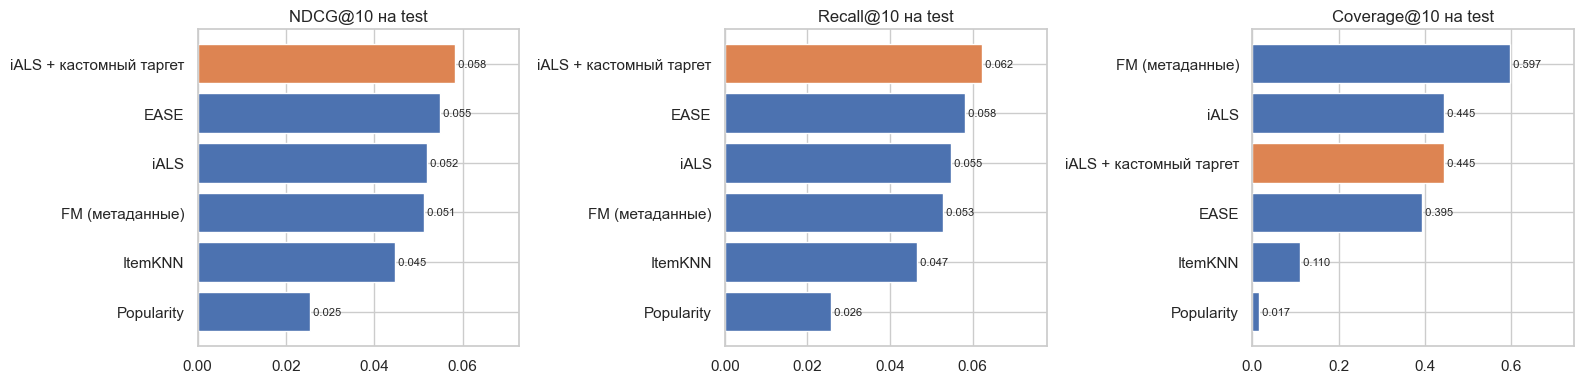

In [19]:
main = [n for n in test_table.index if n != "FM без метаданных"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, metric in zip(ax, [MAIN_METRIC, f"Recall@{K}", f"Coverage@{K}"]):
    vals = test_table.loc[main, metric].sort_values()
    a.barh(vals.index, vals.values, color=["#4C72B0" if "кастом" not in n else "#DD8452" for n in vals.index])
    for i, v in enumerate(vals.values):
        a.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    a.set(title=f"{metric} на test", xlim=(0, vals.max() * 1.25))
plt.tight_layout(); plt.show()

In [20]:
print(f"Полное время выполнения ноутбука: {(time.time() - T0) / 60:.1f} мин")

Полное время выполнения ноутбука: 55.2 мин


## 6. Выводы

1. Лучший результат у iALS с кастомным целевым сигналом: NDCG@10 = 0.0583, Recall@10 = 0.0623 на test. Это на 12.5% выше базового iALS (0.0518) при тех же $d,\lambda,\alpha$ и той же уверенности. На validation разница похожая (0.0643 против 0.0575), покрытие каталога не изменилось (0.445). Учёт дослушивания, лайков и дизлайков оказался полезнее, чем бинарный признак прослушивания.
2. EASE на втором месте (0.0548) и лучший из методов без кастомного сигнала. Модель обучается в замкнутой форме за несколько секунд.
3. Метаданные в FM не улучшили качество. На validation трековые признаки (исполнитель, альбом, длина, популярность) снижали NDCG: набор `all` дал 0.0505, FM без метаданных - 0.0580. Лучший набор с метаданными - только профиль исполнителей пользователя (0.0570). На test FM с метаданными и без них почти совпадают (0.0513 и 0.0515). Вероятная причина в подвыборке: каталог состоит из популярных треков (не меньше 211 слушателей), матрица плотная (6.8%), и эмбеддинги ID хорошо оцениваются по данным. Метаданные полезнее для холодных и редких треков, которых здесь нет. При этом у FM самое большое покрытие каталога (0.60).
4. Для базового iALS лучшим оказалось малое $\alpha=0.5$, то есть уверенность слабо зависит от числа прослушиваний. Количество прослушиваний знакомого трека мало говорит об интересе к новым трекам.
5. ItemKNN уступает факторизационным моделям и EASE (0.0448) и покрывает только 11% каталога. Логарифмические веса лучше бинарных для kNN и EASE. Все персонализированные модели в 1.8-2.3 раза лучше бейзлайна по популярности (0.0253).

Ограничения:
* одно окно test (14 дней) и одна подвыборка из популярных треков, холодный старт не оценивается;
* часть событий вызвана рекомендациями сервиса (`is_organic = 0`), поэтому офлайн-оценка смещена в сторону того, что показывала исходная система;
* лучшее $\alpha$ у iALS находится на границе сетки, NDCG у FM меняется от эпохи к эпохе, поэтому выбор числа эпох шумный;
* параметры кастомного таргета подбирались на одном окне validation.